In [192]:
from langgraph.store.base import BaseStore
from langgraph.store.memory import InMemoryStore
from dotenv import load_dotenv
from langchain_core.runnables import RunnableConfig
from langchain_core.messages import SystemMessage,HumanMessage
from langgraph.graph import StateGraph ,START,END,MessagesState
from langchain_groq import ChatGroq
from pydantic import BaseModel , Field
from uuid import uuid4
load_dotenv()

True

In [193]:
model = ChatGroq(model="openai/gpt-oss-20b",
    temperature=0.7)

In [194]:
store = InMemoryStore()

In [195]:
class memoryDecisions(BaseModel):
    worth_storing:bool=Field(description="is this information holds critical information about the user worth storing?")
    memories:list=Field(default_factory=list,description="memories of the user")

In [196]:
memory_fetcher = model.with_structured_output(memoryDecisions)

In [197]:
def memories_decisions_node(state:MessagesState,config:RunnableConfig,store:BaseStore):
    user_id = config['configurable']['user_id']
    namespace = ("user",user_id,"memories")
    last_msg = state['messages'][-1].content

    decisions:memoryDecisions = memory_fetcher.invoke(
        [
            SystemMessage(
                content=(
                    "if the message of the user contains some critical and important information about the user that holds some particular information about the user such as(his name , likings , prefrences , studies and many more ) , that is worth storing , extract them and store that in your own language in a single atomic sentence."
                )
            ),
            HumanMessage(content=last_msg),
        ]
    )
    if decisions.worth_storing:
        for mem in decisions.memories:
            store.put(namespace,str(uuid4()),{'data':mem})

    return {"messages":[{"role":"assistant","content":"noted"}]}

In [198]:
graph = StateGraph(MessagesState)

graph.add_node("memories_decisions_node",memories_decisions_node)
graph.add_edge(START,"memories_decisions_node")

finalGraph = graph.compile(store = store)

In [199]:
config = {"configurable":{"user_id":"u1"}}
res = finalGraph.invoke(
    {
        "messages": [
            HumanMessage(content="my name is saransh")
        ]
    },
    config=config,
)

res['messages'][-1].content

'noted'

In [200]:
res = finalGraph.invoke(
    {
        "messages": [
            HumanMessage(content="i likes coding in python")
        ]
    },
    config=config,
)

res['messages'][-1].content

'noted'

In [201]:
res = finalGraph.invoke(
    {
        "messages": [
            HumanMessage(content="i loves watching football ")
        ]
    },
    config=config,
)

res['messages'][-1].content

'noted'

In [202]:
namespace = ('user','u1','memories')
items = store.search(namespace)
for item in items:
    print(item.value['data'])


The user is named Saransh.
User likes coding in python
The user loves watching football.


STORING MEMORIES WITHOUT DUPLICATE MEMORIES


In [203]:
class memoryItem(BaseModel):
    text:str=Field(description="atomic value of the user's memory")
    is_new :bool=Field(description="is this a new memory or already present in the memories")

In [204]:
class memoryDecisions(BaseModel):
    worth_storing:bool=Field(description="is this information holds critical information about the user worth storing?")
    memories:list[memoryItem]=Field(default_factory=list,description="memories of the user")

In [205]:
SYSTEM_PROMPT = """
You are a memory extraction and deduplication assistant.

Your task is to inspect the user's latest message and the user's existing memories.

1. Decide whether the latest message contains important, durable information about the user that is worth storing. Examples include the user's name, preferences, likes, dislikes, interests, studies, work, location, goals, or other stable personal facts. Do not store greetings, small talk, temporary requests, opinions about unrelated topics, or information that is not about the user.
2. If the message contains useful personal information, extract each fact in your own words as one clear, concise, atomic sentence. Each sentence must express exactly one fact and must be understandable without the original message.
3. Compare every extracted fact with the existing memories. Mark `is_new` as true only when the fact is not already stored and does not duplicate or substantially restate an existing memory. Mark it as false when the same fact, or an equivalent fact, is already present.
4. Return an empty memories list when the message contains no durable personal information.
5. Do not invent, infer, or add facts that the user did not state.

Return only the structured output requested by the schema. Set `worth_storing` to true when at least one durable personal fact is present, even if all extracted facts are duplicates. Set `is_new` independently for each extracted memory.
here are the current all memories-{current_memories}
"""

memory_fetcher = model.with_structured_output(memoryDecisions)

In [206]:
store2 = InMemoryStore()

In [ ]:
def memories_decisions_node_new(state:MessagesState,config:RunnableConfig,store:BaseStore):
    user_id = config['configurable']['user_id']
    namespace = ("user",user_id,"memories")
    last_msg = state['messages'][-1].content
    current_memories = store2.search(namespace)
    if current_memories:
        for mem in current_memories:
            memories_text = "\n".join(f"-{mem.value}")
    else:
        memories_text = ""
    decisions:memoryDecisions = memory_fetcher.invoke(
        [
            SystemMessage(
                content=(SYSTEM_PROMPT.format(current_memories=memories_text))
            ),
            HumanMessage(content=last_msg),
        ]
    )
    if decisions.worth_storing:
        for mem in decisions.memories:
            if mem.is_new:
                store2.put(namespace,str(uuid4()),{'data':mem})

    return {"messages":[{"role":"assistant","content":"noted"}]}


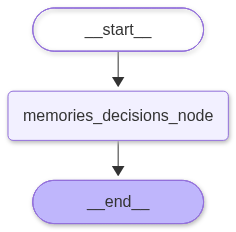

In [ ]:
graph2 = StateGraph(MessagesState)

graph2.add_node("memories_decisions_node",memories_decisions_node_new)
graph2.add_edge(START,"memories_decisions_node")

finalGraph = graph2.compile(store=store2)
finalGraph

In [209]:
config = {"configurable":{"user_id":"u1"}}
res = finalGraph.invoke(
    {
        "messages": [
            HumanMessage(content="my name is saransh")
        ]
    },
    config=config,
)

res['messages'][-1].content

'noted'

In [210]:
config = {"configurable":{"user_id":"u1"}}
res = finalGraph.invoke(
    {
        "messages": [
            HumanMessage(content="my name is saransh")
        ]
    },
    config=config,
)

res['messages'][-1].content

'noted'

In [216]:
config = {"configurable":{"user_id":"u1"}}
res = finalGraph.invoke(
    {
        "messages": [
            HumanMessage(content="i like mountains ")
        ]
    },
    config=config,
)

res['messages'][-1].content

'noted'

In [214]:
config = {"configurable":{"user_id":"u1"}}
res = finalGraph.invoke(
    {
        "messages": [
            HumanMessage(content="i prefers to visit mountains often. ")
        ]
    },
    config=config,
)

res['messages'][-1].content

'noted'

In [217]:
items = store2.search(namespace)
for item in items:
    print(item.value['data'])

text='The user’s name is Saransh.' is_new=True
text='The user likes mountains.' is_new=True
